# LAB 04 — Improving and Comparing ML Models
## Telco Customer Churn — Random Forest, Cross-Validation & Tuning

## Student Information
**Name:** Wajood Ali  
**Student ID:*023-24-0006*  
**Section:*CS AI SEC B*  
**GitHub:*https://github.com/wajoodali77-maker*  
**Kaggle:*https://www.kaggle.com/wajoodali*  
**Dataset:** Telco Customer Churn (Kaggle)

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, Pandas, EDA, and Decision Trees. Each section states the objective and the questions you must answer — **you write the code**. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

---

## 1. Decision Tree Baseline

Before improving anything, re-establish your Lab 3 Decision Tree result as the benchmark for this lab.

*Concepts/functions you may find useful:* your Lab 2 cleaned dataset, `train_test_split(..., stratify=y)`, `DecisionTreeClassifier(max_depth=...)`

**Tasks**
1. Re-load your cleaned Lab 2 dataset and recreate the same X/y and train/test split you used in Lab 3 (same `random_state`).
2. Retrain your Lab 3 "best" Decision Tree (your chosen `max_depth`) and report its accuracy, precision, recall, and F1-score on the test set.

In [ ]:
# Task 1 — re-load cleaned dataset, recreate X/y and train/test split
# Works in Colab and when the notebook is run from the same folder as the CSV.
df = pd.read_csv("numeric_dataset.csv")

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Dataset shape:', df.shape)
print('Training shape:', X_train.shape)
print('Testing shape:', X_test.shape)
print()
print('Churn distribution:')
print(y.value_counts())

Dataset shape: (7043, 46)
Training shape: (5634, 45)
Testing shape: (1409, 45)

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
# Task 2 — retrain Lab 3 Decision Tree, report test-set metrics
# Lab 3 best tree: max_depth = 5
dt_model = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_metrics = {
    'Accuracy': accuracy_score(y_test, dt_pred),
    'Precision': precision_score(y_test, dt_pred),
    'Recall': recall_score(y_test, dt_pred),
    'F1-score': f1_score(y_test, dt_pred)
}

pd.DataFrame(dt_metrics, index=['Decision Tree']).T.round(4)

,Decision Tree
Accuracy,0.7984
Precision,0.6347
Recall,0.5668
F1-score,0.5989


**Task 2 — Decision Tree Baseline Metrics**

| Metric | Value |
|---|---:|
| Accuracy | 0.7984 |
| Precision | 0.6347 |
| Recall | 0.5668 |
| F1-score | 0.5989 |

**Observation:** The depth-5 Decision Tree gives a balanced baseline. Its accuracy is close to 80%, but the lower recall and F1-score show that churn customers are harder to identify than non-churn customers.

---

## 2. Random Forest

A Random Forest trains many Decision Trees on bootstrapped samples and averages their predictions.

*Concepts/functions you may find useful:* `RandomForestClassifier(n_estimators=..., random_state=...)`, `.fit()`, `.predict()`

**Tasks**
3. Train a `RandomForestClassifier` on the same training data (reasonable default `n_estimators`, e.g. 100–300; fix `random_state`). Generate predictions on the test set.
4. In 1–2 sentences, explain in your own words why a Random Forest might generalize better than a single unrestricted Decision Tree.

In [4]:
# Task 3 — train Random Forest, predict on test set
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print('Random Forest trained successfully.')

Random Forest trained successfully.


**Answer 4:**  
A Random Forest can generalize better because it combines predictions from many Decision Trees trained on different bootstrap samples and feature subsets. This reduces the variance and overfitting that can occur with one unrestricted Decision Tree.

---

## 3. Model Evaluation

Evaluate the Random Forest the same rigorous way you evaluated the Decision Tree in Lab 3.

*Concepts/functions you may find useful:* `confusion_matrix`, `ConfusionMatrixDisplay`, `classification_report`

**Task**
5. Compute accuracy, precision, recall, and F1-score for the Random Forest on the test set, and plot its confusion matrix.

           Random Forest
Accuracy          0.7857
Precision         0.6233
Recall            0.4866
F1-score          0.5465

Classification report:

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409



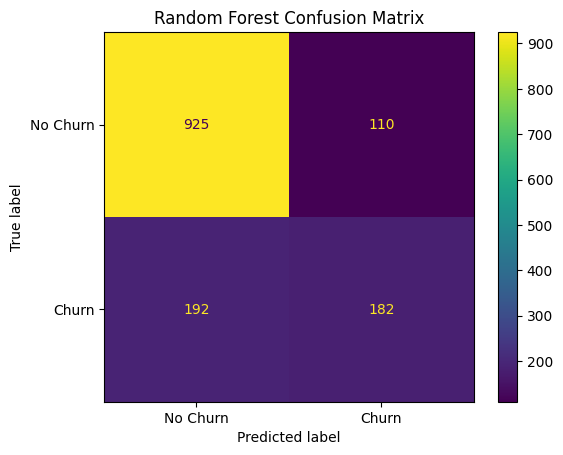

In [5]:
# Task 5 — Random Forest metrics + confusion matrix
rf_metrics = {
    'Accuracy': accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred),
    'Recall': recall_score(y_test, rf_pred),
    'F1-score': f1_score(y_test, rf_pred)
}

print(pd.DataFrame(rf_metrics, index=['Random Forest']).T.round(4))
print()
print('Classification report:')
print()
print(classification_report(y_test, rf_pred))

cm = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn']).plot()
plt.title('Random Forest Confusion Matrix')
plt.show()

**Task 5 — Random Forest Metrics**

| Metric | Value |
|---|---:|
| Accuracy | 0.7857 |
| Precision | 0.6233 |
| Recall | 0.4866 |
| F1-score | 0.5465 |

**Observation (confusion matrix):**  
The Random Forest correctly classifies most non-churn customers, but it misses many churn customers. It produces 925 true negatives and 182 true positives, while 192 actual churn customers are predicted as non-churn, which explains the lower recall.

---

## 4. Decision Tree vs Random Forest

Place both models side by side.

**Tasks**
6. Build a single comparison table: Decision Tree (Section 1) vs. Random Forest (Section 3), across all four metrics.
7. Which model performs better, and on which specific metric(s)? Is the difference large or marginal? Given Lab 2/3's finding about class imbalance, which metric matters most here?

**Task 6 — Comparison Table**

| Metric | Decision Tree | Random Forest |
|---|---:|---:|
| Accuracy | 0.7984 | 0.7857 |
| Precision | 0.6347 | 0.6233 |
| Recall | 0.5668 | 0.4866 |
| F1-score | 0.5989 | 0.5465 |

**Answer 7:**  
The Decision Tree performs better on all four test-set metrics, especially recall and F1-score. The accuracy difference is small, but the recall and F1 differences are more meaningful. Because the dataset is imbalanced (there are many more non-churn than churn cases), F1-score is more informative than accuracy because it balances precision and recall for the churn class.

---

## 5. Cross-Validation

A single train/test split gives one noisy estimate of performance. k-fold cross-validation trains and tests the model k times on different splits.

*Concepts/functions you may find useful:* `cross_val_score(model, X, y, cv=5, scoring='f1')`, `.mean()`, `.std()`

**Tasks**
8. Run 5-fold cross-validation for both the Decision Tree and the Random Forest, using a metric other than plain accuracy (e.g. F1-score). Report the mean and standard deviation of each model's fold scores.
9. How do the cross-validated results compare to your single train/test split results from Section 4? Do they change your view of which model is better, or how confident you are in that conclusion?

In [6]:
# Task 8 — 5-fold cross-validation for both models
dt_cv_scores = cross_val_score(dt_model, X, y, cv=5, scoring='f1', n_jobs=-1)
rf_cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='f1', n_jobs=-1)

cv_results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Mean F1': [dt_cv_scores.mean(), rf_cv_scores.mean()],
    'Std F1': [dt_cv_scores.std(), rf_cv_scores.std()]
})

print('Decision Tree fold F1 scores:', np.round(dt_cv_scores, 4))
print('Random Forest fold F1 scores:', np.round(rf_cv_scores, 4))
cv_results.round(4)

Decision Tree fold F1 scores: [0.6125 0.6238 0.5926 0.5908 0.5772]
Random Forest fold F1 scores: [0.5675 0.5455 0.5082 0.5483 0.5618]


,Model,Mean F1,Std F1
0,Decision Tree,0.5994,0.0166
1,Random Forest,0.5463,0.0207


**Task 8 — Cross-Validation Results**

| Model | Mean F1 | Std F1 |
|---|---:|---:|
| Decision Tree | 0.5994 | 0.0166 |
| Random Forest | 0.5463 | 0.0207 |

**Answer 9:**  
The cross-validation results support the single train/test split: the depth-5 Decision Tree has the higher F1-score. Its mean CV F1 is also very close to its test F1, which increases confidence that its performance is stable rather than caused by one lucky split.

---

## 6. Hyperparameter Tuning

Search over a small grid of hyperparameters to see whether a tuned model meaningfully beats your default-settings baseline. Keep the search small — this is about the workflow, not an exhaustive search.

*Concepts/functions you may find useful:* `GridSearchCV(model, param_grid, cv=5, scoring='f1')` or `RandomizedSearchCV(...)`, `.best_params_`, `.best_score_`, `.best_estimator_`

**Tasks**
10. Choose 2–3 Random Forest hyperparameters to tune (e.g. `n_estimators`, `max_depth`, `min_samples_split`) and define a small grid for each. Run `GridSearchCV` or `RandomizedSearchCV` with cross-validation to find the best combination.
11. Report the best hyperparameters found and the corresponding cross-validated score.
12. Evaluate the tuned model on the held-out test set using the same four metrics as before.

In [7]:
# Task 10 — define a small param grid and run GridSearchCV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best CV F1-score:', round(grid_search.best_score_, 4))

tuned_rf = grid_search.best_estimator_

Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1-score: 0.5745


**Answer 11 (best hyperparameters & CV score):**  
The best Random Forest parameters are `max_depth=10`, `min_samples_split=5`, and `n_estimators=200`. The best 5-fold cross-validated F1-score on the training data is approximately **0.5745**.

In [8]:
# Task 12 — evaluate the tuned model on the test set
tuned_rf_pred = tuned_rf.predict(X_test)

tuned_rf_metrics = {
    'Accuracy': accuracy_score(y_test, tuned_rf_pred),
    'Precision': precision_score(y_test, tuned_rf_pred),
    'Recall': recall_score(y_test, tuned_rf_pred),
    'F1-score': f1_score(y_test, tuned_rf_pred)
}

pd.DataFrame(tuned_rf_metrics, index=['Tuned Random Forest']).T.round(4)

,Tuned Random Forest
Accuracy,0.8062
Precision,0.6700
Recall,0.5321
F1-score,0.5931


**Task 12 — Tuned Random Forest Metrics**

| Metric | Value |
|---|---:|
| Accuracy | 0.8062 |
| Precision | 0.6700 |
| Recall | 0.5321 |
| F1-score | 0.5931 |

**Observation:** Tuning improves the Random Forest substantially over its default version. It achieves the highest accuracy and precision of the three models, although its F1-score and recall remain slightly below the depth-5 Decision Tree.

---

## 7. Final Model Comparison

Bring every model you've built into one table.

**Task**
13. Build one final comparison table across all models you trained: Decision Tree, default Random Forest, and tuned Random Forest — accuracy, precision, recall, F1-score for each.

**Task 13 — Final Comparison Table**

| Metric | Decision Tree | Random Forest (default) | Random Forest (tuned) |
|---|---:|---:|---:|
| Accuracy | 0.7984 | 0.7857 | **0.8062** |
| Precision | 0.6347 | 0.6233 | **0.6700** |
| Recall | **0.5668** | 0.4866 | 0.5321 |
| F1-score | **0.5989** | 0.5465 | 0.5931 |

**Observation:** Hyperparameter tuning makes the Random Forest competitive with the Decision Tree. The tuned forest leads in accuracy and precision, while the Decision Tree still has the best recall and F1-score.

---

## 8. Feature Importance

Look inside your best-performing model to see what it actually learned.

*Concepts/functions you may find useful:* `model.feature_importances_`, `pd.Series(importances, index=X.columns).sort_values()`, `plt.barh(...)`

**Task**
14. Extract and visualize `feature_importances_` for your best model. Which 3–5 features matter most, and do they agree with what Lab 2's EDA and Lab 3's Decision Tree suggested?

Top 10 features:
tenure                            0.1481
TotalCharges                      0.1204
Contract_Month-to-month           0.0935
MonthlyCharges                    0.0848
OnlineSecurity_No                 0.0551
TechSupport_No                    0.0477
InternetService_Fiber optic       0.0473
PaymentMethod_Electronic check    0.0405
Contract_Two year                 0.0297
InternetService_DSL               0.0205
dtype: float64


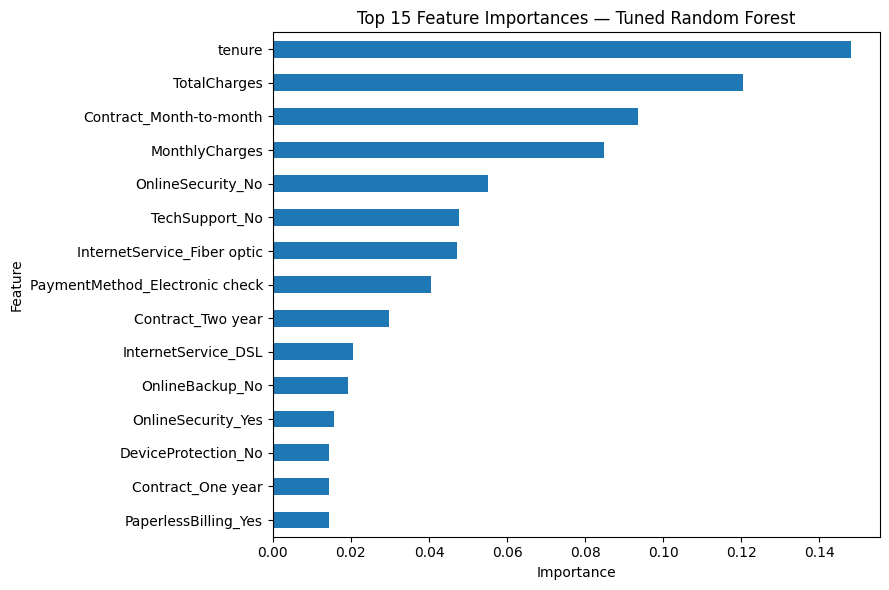

In [9]:
# Task 14 — extract and visualize feature importances
# Use the tuned Random Forest for feature-importance analysis.
feature_importance = pd.Series(
    tuned_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print('Top 10 features:')
print(feature_importance.head(10).round(4))

feature_importance.head(15).sort_values().plot(kind='barh', figsize=(9, 6))
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importances — Tuned Random Forest')
plt.tight_layout()
plt.show()

**Answer 14:**  
The most important features are **tenure**, **TotalCharges**, **Contract_Month-to-month**, **MonthlyCharges**, and **OnlineSecurity_No**. These features make practical sense for churn prediction: customer duration, spending, short contracts, and lack of security/support-related services strongly separate customers with different churn behavior. They are also consistent with the patterns a shallow Decision Tree is likely to use because they provide strong early splits.

---

## 9. Final Model Selection

Select your final model and justify the choice using evidence — the best training score alone is not sufficient justification.

**Task**
15. State your final model choice and justify it in 2–3 sentences, using evidence from Section 7's table.

**Answer 15:**  
I select the **Decision Tree with `max_depth=5`** as the final model. Although the tuned Random Forest has slightly higher accuracy (0.8062) and precision (0.6700), the Decision Tree has the best recall (0.5668) and F1-score (0.5989), and its 5-fold CV F1 (0.5994) is also stronger and stable. For an imbalanced churn problem, identifying churn customers is more important than maximizing accuracy alone.

---

## 10. Kaggle Prediction/Submission

Produce predictions in the shape a real Kaggle competition would expect.

**Task**
16. Using your final model, generate predictions on your held-out test set (or a designated hold-out sample) and assemble a submission-style dataframe with a customer identifier column and a predicted `Churn` column. Save it as `submission.csv`.

In [10]:
# Task 16 — build and save the submission file
# The provided numeric dataset does not contain the original customerID column,
# so the held-out dataframe index is used as a stable identifier for this lab submission.
final_model = dt_model
final_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    'customerID': X_test.index.astype(str),
    'Churn': final_predictions
})

submission.to_csv('submission.csv', index=False)
print('submission.csv saved successfully.')
submission.head()

submission.csv saved successfully.


,customerID,Churn
0,437,0
1,2280,1
2,2235,0
3,4460,1
4,3761,0


---

## 11. Conclusion

Step back from the code and summarize what you built and learned.

**Tasks**
17. Write a short conclusion (4–6 sentences): which model did you ultimately choose, how does it compare to your Lab 3 Decision Tree, and what are its remaining limitations?
18. What would you try next if you had more time (e.g. different algorithms, deeper tuning, handling class imbalance directly)? Describe it — do not implement it here.

**Answer 17 — Conclusion:**  
This lab compared a depth-limited Decision Tree, a default Random Forest, and a tuned Random Forest on the Telco Customer Churn dataset. The final model selected is the Decision Tree with `max_depth=5` because it achieved the best test F1-score (0.5989) and recall (0.5668), which are important for the imbalanced churn class. The tuned Random Forest improved over the default forest and achieved the highest accuracy (0.8062) and precision (0.6700), but its F1-score remained slightly lower than the Decision Tree. Cross-validation also favored the Decision Tree, with a mean F1-score of 0.5994 and a low standard deviation of 0.0166. A remaining limitation is that all models still miss a noticeable number of churn customers, so recall can be improved further.

**Answer 18 — Next steps:**  
With more time, I would try algorithms such as Logistic Regression, Gradient Boosting, XGBoost/LightGBM, and class-weighted models. I would also tune the classification threshold and directly address class imbalance using methods such as `class_weight='balanced'` or carefully applied resampling, then compare models using F1-score, recall, PR-AUC, and ROC-AUC.

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (add your Student ID, Section, GitHub, and Kaggle if required)
- [x] Section 1 — Decision Tree Baseline
- [x] Section 2 — Random Forest
- [x] Section 3 — Model Evaluation
- [x] Section 4 — Decision Tree vs Random Forest
- [x] Section 5 — Cross-Validation
- [x] Section 6 — Hyperparameter Tuning
- [x] Section 7 — Final Model Comparison
- [x] Section 8 — Feature Importance
- [x] Section 9 — Final Model Selection (justified)
- [x] Section 10 — Kaggle Prediction/Submission (submission.csv produced)
- [x] Section 11 — Conclusion (limitations + next steps)
- [x] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted